# Credit Pre-Screening Engine — Loan Intake Optimisation
### Calibo AI Academy · Phase 2, Mini Use Case 02 · Supervised Learning Part 1 (Logistic Regression)
**BFSI — Retail Lending**

**Team:** Batch_15

| Member | Student ID | Role | Sections owned |
|---|---|---|---|
| Velagapudi Haritha | 2300030248 | Data Analyst | CBIM Canvas, Step 5.1, Step 5.2, Step 5.3 |
| Kunapuli Bala Sri Sarvani | 2300030957 | Model Builder | Step 5.4, Step 5.5 |
| Yaswanth Kumar Reddy Vogireddy | 2300031126 | Policy Synthesiser | Step 5.6, Step 5.7 |

**Dataset:** `MUC02_Credit_PreScreening_Dataset.csv` — 12,000 personal loan applications, April–September 2026, 19 columns.

This notebook is the single source of truth for our submission. Every number quoted in our individual reflections, our team insight summary and our presentation deck is taken directly from the cells below.

---
## CBIM Problem Canvas
*Owned by: Velagapudi Haritha (Data Analyst)*

| Field | Our answer |
|---|---|
| **Situation (S)** | A mid-size retail bank receives roughly 3,000 personal loan applications a month. Every single one is currently reviewed manually by a credit analyst, taking about 25 minutes per application. |
| **Complication (C)** | Analyst time is spent reviewing applications that are, in hindsight, clear-cut declines, while genuinely strong applicants wait longer in the same queue. The bank cannot keep scaling this process by simply hiring more analysts. |
| **Question (Q)** | Which applications can be safely removed from manual review — and at what confidence threshold — without wrongly auto-declining more than 5% of applicants the credit team would actually have approved? |
| **SSOT (Single Source of Truth)** | `MUC02_Credit_PreScreening_Dataset.csv`. Important caveat: the `decision` column records the credit team's *past judgement*, not whether the loan was actually repaid. A model trained on this label learns to imitate the analysts — including any bias already present in their decisions. |
| **Success definition** | A single auto-decline threshold that respects the bank's 5% wrong-decline risk limit, with a clearly stated number of applications and analyst-hours per month that it frees up. |
| **Primary stakeholder** | The Credit Policy Analyst commissioning this work — and, downstream, the analysts whose day-to-day workload changes, the Head of Retail Lending who owns the risk appetite, and the loan applicants whose outcomes are affected. |

**Why the SSOT caveat matters:** because the target variable is a human decision and not a repayment outcome, our model's job is strictly to flag applications that *look like* the easy declines analysts already make — not to re-litigate whether those past declines were the right call. This shapes everything downstream, especially the fairness check in Step 5.6.

---
## Step 5.1 — Load, Inspect and Clean the Data
*Owned by: Velagapudi Haritha (Data Analyst)*

We start by loading the raw file and taking an honest look at its quality before touching anything else.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.width', 120)
sns.set_style('whitegrid')

# One consistent palette used across every chart in this notebook
PALETTE = {'low': '#C0392B', 'mid': '#E67E22', 'high': '#27AE60', 'neutral': '#2C3E6B', 'accent': '#7F8C8D'}

df = pd.read_csv("MUC02_Credit_PreScreening_Dataset 1.csv")
print("Shape:", df.shape)
df.head()

Shape: (12000, 19)


,application_id,application_date,age,gender,city,city_tier,employment_type,years_in_current_job,monthly_income,existing_emi,credit_score,credit_history_months,num_active_loans,delinquencies_24m,loan_purpose,loan_amount,tenure_months,proposed_emi,decision
0,APP100001,2026-04-01,28,Male,Hyderabad,1,Salaried,4.1,95000.0,23500.0,784.0,109,2,0,Home Renovation,240000.0,48,6600.0,Approved
1,APP100002,2026-04-01,36,Female,Raipur,3,Business Owner,0.6,43000.0,8500.0,790.0,162,2,0,Wedding,145000.0,36,5000.0,Approved
2,APP100003,2026-04-01,35,Male,Nagpur,2,Salaried,4.4,35000.0,3500.0,718.0,151,1,1,Medical,345000.0,36,11800.0,Approved
3,APP100004,2026-04-01,42,Male,Jaipur,2,Salaried,5.8,44500.0,0.0,NaN,0,0,0,Travel,135000.0,36,4600.0,Approved
4,APP100005,2026-04-01,34,Male,Kochi,2,Self-Employed Professional,2.1,83500.0,6000.0,700.0,127,1,3,Medical,700000.0,24,33600.0,Declined


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 19 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   application_id         12000 non-null  str    
 1   application_date       12000 non-null  str    
 2   age                    12000 non-null  int64  
 3   gender                 12000 non-null  str    
 4   city                   12000 non-null  str    
 5   city_tier              12000 non-null  int64  
 6   employment_type        12000 non-null  str    
 7   years_in_current_job   12000 non-null  float64
 8   monthly_income         11559 non-null  float64
 9   existing_emi           12000 non-null  float64
 10  credit_score           10961 non-null  float64
 11  credit_history_months  12000 non-null  int64  
 12  num_active_loans       12000 non-null  int64  
 13  delinquencies_24m      12000 non-null  int64  
 14  loan_purpose           12000 non-null  str    
 15  loan_amount  

In [3]:
null_counts = df.isnull().sum()
print(null_counts[null_counts > 0])

approval_rate = (df['decision'] == 'Approved').mean() * 100
print(f"\nOverall approval rate: {approval_rate:.1f}%")

monthly_income     441
credit_score      1039
dtype: int64

Overall approval rate: 52.9%


### Cleaning log

We found three data-quality issues and handled each on its own merits rather than blanket-dropping nulls.

**Issue 1 — `monthly_income` missing in 441 rows.** Before fixing anything, we checked *who* these rows belong to.

In [4]:
miss_income = df[df['monthly_income'].isnull()]
print(miss_income['employment_type'].value_counts())
print()
print("Share missing within each employment type:")
print((miss_income['employment_type'].value_counts() / df['employment_type'].value_counts() * 100).round(1))

employment_type
Business Owner                227
Self-Employed Professional    154
Salaried                       49
Gig / Contract                 11
Name: count, dtype: int64

Share missing within each employment type:
employment_type
Business Owner                13.0
Gig / Contract                 0.6
Salaried                       0.7
Self-Employed Professional    10.8
Name: count, dtype: float64


**Finding:** missing income is concentrated in **Business Owner (13.0%)** and **Self-Employed Professional (10.8%)** applicants — it is not random. Self-employed applicants are far more likely to skip or not have a clean monthly income figure to declare.

**Fix:** impute with the median income *for that applicant's employment type* (not the overall median), so we don't drag self-employed incomes toward the salaried median.

In [5]:
median_by_emp = df.groupby('employment_type')['monthly_income'].median()
print(median_by_emp)

df['monthly_income'] = df.apply(
    lambda r: median_by_emp[r['employment_type']] if pd.isnull(r['monthly_income']) else r['monthly_income'],
    axis=1
)
print("\nRemaining nulls in monthly_income:", df['monthly_income'].isnull().sum())

employment_type
Business Owner                69500.0
Gig / Contract                28000.0
Salaried                      50000.0
Self-Employed Professional    75000.0
Name: monthly_income, dtype: float64

Remaining nulls in monthly_income: 0


**Issue 2 — `credit_score` missing in 1,039 rows (8.7% of all applicants).** The temptation here is to drop these rows. We checked `credit_history_months` for this group first.

In [6]:
miss_score = df[df['credit_score'].isnull()]
print("Rows missing credit_score:", len(miss_score))
print("Of those, credit_history_months == 0:", (miss_score['credit_history_months'] == 0).sum())
print("Approval rate among this group:", round((miss_score['decision']=='Approved').mean()*100, 1), "%")

Rows missing credit_score: 1039
Of those, credit_history_months == 0: 1039
Approval rate among this group: 53.9 %


**Finding:** every single one of these 1,039 applicants has `credit_history_months == 0`. These are not data errors — they are genuine **new-to-credit (NTC)** applicants who have never had a credit history to score. Dropping them would silently remove 8.7% of our applicant base (likely skewed younger) from the analysis entirely.

Notably, the credit team still approves **53.9%** of NTC applicants — essentially a coin-flip — which tells us the credit team is already using judgement calls beyond the credit score for this group.

**Decision:** we keep every one of these rows. We will formally flag them with an `is_ntc` column when we engineer features in Step 5.3, and fill `credit_score` with the population median for modelling purposes in Step 5.4 — `is_ntc` is what tells the model which scores were filled.

**Issue 3 — a small number of implausibly large `monthly_income` values.** We inspected the maximum value directly.

In [7]:
print("Maximum monthly_income:", df['monthly_income'].max())
implausible = df[df['monthly_income'] > 600000]
print(len(implausible), "rows above ₹6,00,000/month")
print(implausible['employment_type'].value_counts())
print(implausible[['monthly_income','employment_type']].head())

Maximum monthly_income: 1656000.0
12 rows above ₹6,00,000/month
employment_type
Salaried    12
Name: count, dtype: int64
      monthly_income employment_type
300        1254000.0        Salaried
589        1068000.0        Salaried
1467       1656000.0        Salaried
1848        984000.0        Salaried
2488        972000.0        Salaried


**Finding:** all 12 are **Salaried** applicants, and the values are consistent with *annual* income having been entered into the monthly field by mistake (e.g. ₹5,46,000 would be a very reasonable *annual* salary but an impossible monthly one).

**Fix:** divide these 12 values by 12 rather than drop them — they are usable data once corrected.

In [8]:
fix_mask = df['monthly_income'] > 600000
df.loc[fix_mask, 'monthly_income'] = df.loc[fix_mask, 'monthly_income'] / 12
print("Max monthly_income after fix:", df['monthly_income'].max())

Max monthly_income after fix: 546000.0


**Cleaning summary:** 12,000 rows retained throughout — we did not drop a single applicant. 441 incomes imputed by employment-type median, 1,039 NTC applicants kept (to be flagged in Step 5.3 and median-filled for modelling in Step 5.4), 12 income values corrected from an annual→monthly entry error. Keeping the NTC group rather than dropping it is the single most consequential cleaning choice in this notebook.

---
## Step 5.2 — What Drives Approval Today?
*Owned by: Velagapudi Haritha (Data Analyst)*

Before building any model, we look at how the credit team's existing decisions actually break down.

In [9]:
scored = df[df['credit_score'].notnull()].copy()
score_bins = [0, 599, 649, 699, 749, 799, 900]
score_labels = ['<600', '600-649', '650-699', '700-749', '750-799', '800+']
scored['score_band'] = pd.cut(scored['credit_score'], bins=score_bins, labels=score_labels)

band_approval = scored.groupby('score_band')['decision'].apply(lambda s: (s=='Approved').mean()*100)
ntc_approval = (df[df['credit_score'].isnull()]['decision']=='Approved').mean()*100

print(band_approval.round(1))
print(f"\nNo score (NTC): {ntc_approval:.1f}% approved")

score_band
<600        2.0
600-649     3.2
650-699    32.5
700-749    54.4
750-799    77.2
800+       85.2
Name: decision, dtype: float64

No score (NTC): 53.9% approved


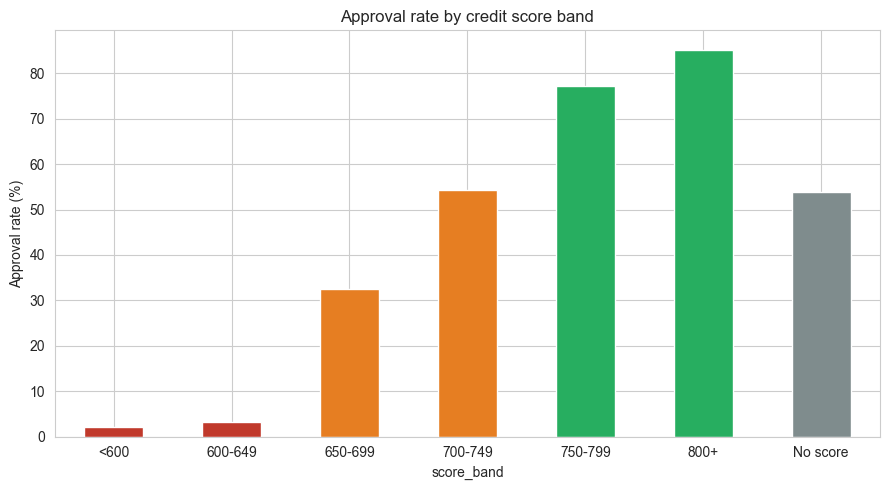

In [10]:
plot_data = band_approval.copy()
plot_data['No score'] = ntc_approval

fig, ax = plt.subplots(figsize=(9,5))
colors = [PALETTE['low']]*2 + [PALETTE['mid']]*2 + [PALETTE['high']]*2 + [PALETTE['accent']]
plot_data.plot(kind='bar', ax=ax, color=colors)
ax.set_ylabel('Approval rate (%)')
ax.set_title('Approval rate by credit score band')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('credit_score_bands.png', dpi=130)
plt.show()

**Interpretation:** this is not just "lower scores get fewer approvals" — there is a **hard, unwritten floor at 650**. Below it, approvals are in the low single digits (2–3%); above it, approval jumps to roughly a third, then climbs steadily to **85.2%** for the 800+ band. A pre-screener can treat "credit score below 650" as a near-automatic decline with very little risk of over-ruling the credit team.

New-to-credit applicants sit right in the *middle* of this curve (53.9% approved) despite having no score at all — confirming the credit team is using manual judgement for this group that a score-driven rule simply cannot replicate.

employment_type
Gig / Contract                34.9
Self-Employed Professional    50.6
Business Owner                51.2
Salaried                      58.4
Name: decision, dtype: float64


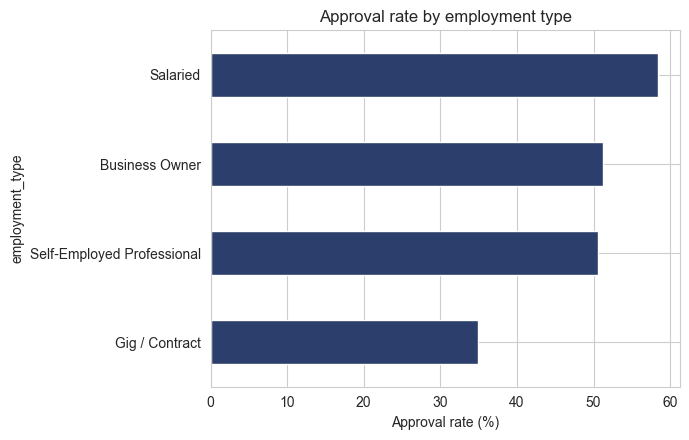

In [11]:
emp_approval = df.groupby('employment_type')['decision'].apply(lambda s: (s=='Approved').mean()*100).sort_values()
print(emp_approval.round(1))

fig, ax = plt.subplots(figsize=(7,4.5))
emp_approval.plot(kind='barh', ax=ax, color=PALETTE['neutral'])
ax.set_xlabel('Approval rate (%)')
ax.set_title('Approval rate by employment type')
plt.tight_layout()
plt.savefig('employment_type_approval.png', dpi=130)
plt.show()

**Interpretation:** **Gig / Contract** applicants are approved only **34.9%** of the time, well below Salaried (**58.4%**) and the two self-employed categories (~50–51%). This is plausibly linked to income irregularity and shorter job tenure rather than the employment label itself.

---
## Step 5.3 — Engineer the Affordability Features
*Owned by: Velagapudi Haritha (Data Analyst)*

The raw columns don't directly capture affordability or credit history status — we build three new columns here, exactly as specified: `foir`, `loan_to_income`, and `is_ntc`.

In [12]:
df['foir'] = (df['existing_emi'] + df['proposed_emi']) / df['monthly_income']
df['loan_to_income'] = df['loan_amount'] / (df['monthly_income'] * 12)
df['is_ntc'] = df['credit_score'].isnull().astype(int)

print(df[['foir','loan_to_income','is_ntc']].describe().round(2))
print("\nis_ntc counts:\n", df['is_ntc'].value_counts())

           foir  loan_to_income    is_ntc
count  12000.00        12000.00  12000.00
mean       0.36            0.53      0.09
std        0.21            0.23      0.28
min        0.00            0.01      0.00
25%        0.21            0.35      0.00
50%        0.32            0.52      0.00
75%        0.45            0.70      0.00
max        3.39            2.78      1.00

is_ntc counts:
 is_ntc
0    10961
1     1039
Name: count, dtype: int64


foir
<30%      65.4
30-40%    59.0
40-50%    47.4
50-55%    31.7
>55%      15.5
Name: decision, dtype: float64


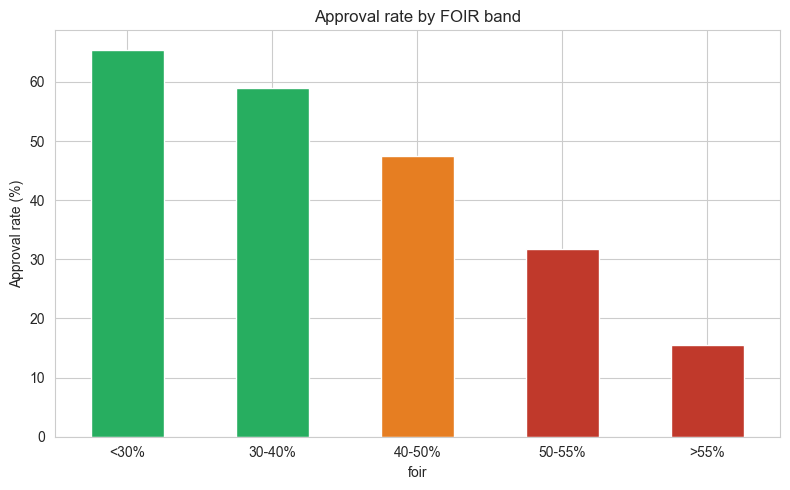

In [13]:
foir_bins = [0, 0.3, 0.4, 0.5, 0.55, 10]
foir_labels = ['<30%','30-40%','40-50%','50-55%','>55%']
foir_bands = pd.cut(df['foir'], bins=foir_bins, labels=foir_labels)
foir_approval = df.groupby(foir_bands)['decision'].apply(lambda s: (s=='Approved').mean()*100)
print(foir_approval.round(1))

fig, ax = plt.subplots(figsize=(8,5))
colors = [PALETTE['high'], PALETTE['high'], PALETTE['mid'], PALETTE['low'], PALETTE['low']]
foir_approval.plot(kind='bar', ax=ax, color=colors)
ax.set_ylabel('Approval rate (%)')
ax.set_title('Approval rate by FOIR band')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('foir_bands.png', dpi=130)
plt.show()

**Interpretation:** FOIR is the single clearest affordability signal in the dataset. Approval falls from **65.4%** when committed obligations are under 30% of income, to **31.7%** in the 50–55% band, to just **15.5%** once obligations pass 55% of income. If we were writing this into a credit policy, we would propose a **FOIR limit of 50–55%** — this is where approvals effectively collapse.

---
## Step 5.4 — Build the Logistic Regression Pre-Screener
*Owned by: Kunapuli Bala Sri Sarvani (Model Builder)*

We predict **Declined = 1** (not Approved) because the business question is about safely *auto-declining* applications. We use exactly the feature set specified: `credit_score`, `is_ntc`, `foir`, `loan_to_income`, `delinquencies_24m`, `num_active_loans`, `years_in_current_job`, `age`, `tenure_months`, `city_tier`, `employment_type` and `loan_purpose`. `application_id`, `application_date`, `city`, `gender` and `decision` are excluded, as instructed.

In [14]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, roc_auc_score, precision_score, recall_score

y = (df['decision'] == 'Declined').astype(int)

# Blank credit scores are filled with the median for modelling — is_ntc tells the model which ones were filled
credit_score_median = df['credit_score'].median()
df['credit_score_filled'] = df['credit_score'].fillna(credit_score_median)
print("Median credit_score used to fill blanks:", credit_score_median)

numeric_features = ['credit_score_filled','is_ntc','foir','loan_to_income','delinquencies_24m',
                     'num_active_loans','years_in_current_job','age','tenure_months','city_tier']
categorical_features = ['employment_type','loan_purpose']

X = pd.get_dummies(df[numeric_features + categorical_features], columns=categorical_features, drop_first=True)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print("Train:", X_train.shape, " Test:", X_test.shape)

Median credit_score used to fill blanks: 726.0
Train: (9600, 19)  Test: (2400, 19)


In [15]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

model = LogisticRegression(max_iter=1000)
model.fit(X_train_s, y_train)

proba = model.predict_proba(X_test_s)[:, 1]
pred_default = (proba >= 0.5).astype(int)

In [16]:
acc = accuracy_score(y_test, pred_default)
prec = precision_score(y_test, pred_default)
rec = recall_score(y_test, pred_default)
tn, fp, fn, tp = confusion_matrix(y_test, pred_default).ravel()

print(f"Accuracy:  {acc:.3f}")
print(f"Precision (Declined): {prec:.3f}")
print(f"Recall (Declined):    {rec:.3f}")
print(f"\nConfusion matrix at 0.5 threshold:")
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")

Accuracy:  0.791
Precision (Declined): 0.791
Recall (Declined):    0.755

Confusion matrix at 0.5 threshold:
TN=1046  FP=225  FN=277  TP=852


**In business language:** at the default 0.5 cut-off, our model would auto-decline a little under half of all applications — but **225 of them are applicants the credit team actually approved**. That is far too costly a mistake rate to automate anything at 0.5 — which is exactly why Step 5.5 exists.

The five features with the largest coefficients (positive = pushes toward Decline):
foir                              1.22
credit_score_filled              -1.01
delinquencies_24m                 0.98
is_ntc                            0.38
employment_type_Gig / Contract    0.23
dtype: float64


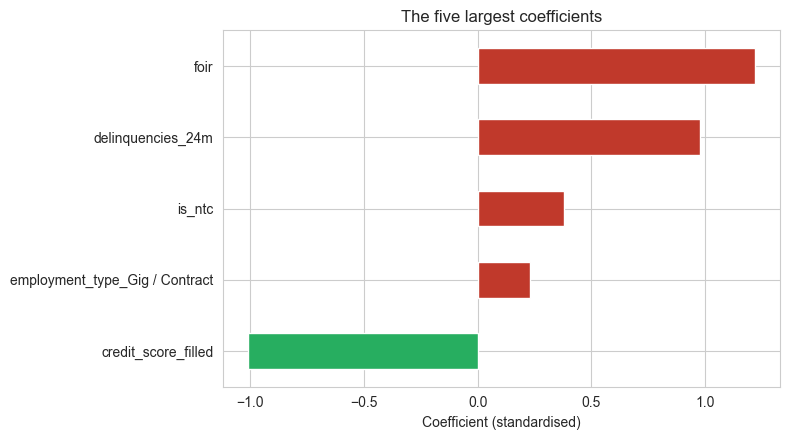

In [17]:
coefs = pd.Series(model.coef_[0], index=X.columns).sort_values(key=abs, ascending=False)
print("The five features with the largest coefficients (positive = pushes toward Decline):")
print(coefs.head(5).round(2))

fig, ax = plt.subplots(figsize=(8,4.5))
top5 = coefs.head(5).sort_values()
colors = [PALETTE['low'] if v>0 else PALETTE['high'] for v in top5]
top5.plot(kind='barh', ax=ax, color=colors)
ax.set_xlabel('Coefficient (standardised)')
ax.set_title('The five largest coefficients')
plt.tight_layout()
plt.savefig('coefficients.png', dpi=130)
plt.show()

**Interpretation for a credit analyst:**

- **FOIR (+1.22)** — the strongest single driver toward decline, consistent with what we found by hand in Step 5.3.
- **Credit score (−1.01)** — a higher score pushes firmly toward approval, consistent with the cliff we found in Step 5.2.
- **Delinquencies in the last 24 months (+0.98)** — every additional missed or late payment pushes the application toward decline.
- **New-to-credit flag (+0.38)** — being new-to-credit pushes toward decline on average, even though the credit team itself approves this group about half the time — a sign the model is working with weaker information for this segment.
- **Gig / Contract employment (+0.23)** — being a gig worker pushes toward decline, echoing the employment-type pattern in Step 5.2.

The model's own coefficients independently confirm the patterns we found by hand — reassurance that it has learned something real, not noise.

---
## Step 5.5 — Set the Auto-Decline Threshold
*Owned by: Kunapuli Bala Sri Sarvani (Model Builder)*

A model that auto-declines everyone predicted "Declined" at the default 0.5 cut-off turns away too many good customers (225 of them, as we just saw). Instead, the bank will only auto-decline when the model is very confident.

In [18]:
thresholds = [0.50, 0.60, 0.70, 0.80, 0.85, 0.90, 0.95]
rows = []
for t in thresholds:
    pred_t = (proba >= t).astype(int)
    n_declined = pred_t.sum()
    pct_declined = n_declined / len(pred_t) * 100
    wrong = ((pred_t == 1) & (y_test == 0)).sum()
    pct_wrong = wrong / n_declined * 100 if n_declined > 0 else 0
    rows.append([t, round(pct_declined,1), round(pct_wrong,1)])

threshold_table = pd.DataFrame(rows, columns=['Threshold','% auto-declined','% wrongly declined'])
threshold_table

,Threshold,% auto-declined,% wrongly declined
0,0.50,44.9,20.9
1,0.60,37.6,16.9
2,0.70,30.8,12.1
3,0.80,23.4,7.1
4,0.85,19.8,6.1
5,0.90,15.2,4.7
6,0.95,10.0,2.1


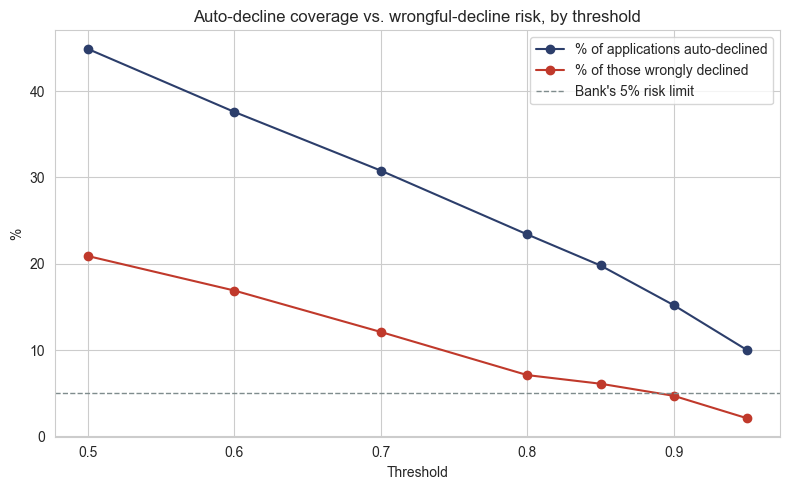

In [19]:
fig, ax = plt.subplots(figsize=(8,5))
ax.plot(threshold_table['Threshold'], threshold_table['% auto-declined'], marker='o', color=PALETTE['neutral'], label='% of applications auto-declined')
ax.plot(threshold_table['Threshold'], threshold_table['% wrongly declined'], marker='o', color=PALETTE['low'], label='% of those wrongly declined')
ax.axhline(5, color=PALETTE['accent'], linestyle='--', linewidth=1, label='Bank\'s 5% risk limit')
ax.set_xlabel('Threshold')
ax.set_ylabel('%')
ax.set_title('Auto-decline coverage vs. wrongful-decline risk, by threshold')
ax.legend()
plt.tight_layout()
plt.savefig('threshold_table.png', dpi=130)
plt.show()

In [20]:
chosen_threshold = 0.90
row = threshold_table[threshold_table['Threshold']==chosen_threshold].iloc[0]
monthly_applications = 3000
auto_declined_per_month = monthly_applications * row['% auto-declined'] / 100
analyst_minutes_per_app = 25
analyst_hours_saved = auto_declined_per_month * analyst_minutes_per_app / 60

print(f"Chosen threshold: {chosen_threshold}")
print(f"% of applications auto-declined: {row['% auto-declined']}%")
print(f"% of those wrongly declined (must be <5%): {row['% wrongly declined']}%")
print(f"\nAt ~{monthly_applications} applications/month:")
print(f"  ~{auto_declined_per_month:.0f} applications auto-declined per month")
print(f"  ~{analyst_hours_saved:.0f} analyst-hours freed per month")

Chosen threshold: 0.9
% of applications auto-declined: 15.2%
% of those wrongly declined (must be <5%): 4.7%

At ~3000 applications/month:
  ~456 applications auto-declined per month
  ~190 analyst-hours freed per month


**Our chosen threshold is 0.90.** We need the highest-coverage threshold that still keeps wrongly-declined applications under the bank's 5% risk limit. At 0.85, wrongly-declined applications are **6.1%** — above the limit, so it fails the rule. At 0.90, that figure drops to **4.7%**, comfortably inside the limit, while still auto-declining **15.2%** of all applications.

Translated into monthly business impact: at roughly 3,000 applications a month, that's about **456 applications** auto-declined, freeing up roughly **190 analyst-hours a month**, with fewer than 1 in 20 of those auto-declines being a customer the bank would actually have approved.

**The teaching point:** at the default 0.5 cut-off, the model would auto-decline nearly 45% of applications, but almost 21% of those would be wrongful declines — unacceptable. The right threshold comes from the bank's stated risk appetite, not from a statistical default of 0.5.

---
## Step 5.6 — Fairness Check
*Owned by: Yaswanth Kumar Reddy Vogireddy (Policy Synthesiser)*

`gender` was never used as a model feature. But "we didn't use gender, so the model is fair" is not a sufficient answer — we need to actually measure outcomes by gender.

In [21]:
print("Raw historical approval rate by gender:")
print(df.groupby('gender')['decision'].apply(lambda s: (s=='Approved').mean()*100).round(1))

print("\nApproval rate by gender, WITHIN each employment type:")
print(df.groupby(['employment_type','gender'])['decision'].apply(lambda s: (s=='Approved').mean()*100).round(1))

Raw historical approval rate by gender:
gender
Female    50.4
Male      54.1
Name: decision, dtype: float64

Approval rate by gender, WITHIN each employment type:
employment_type             gender
Business Owner              Female    51.6
                            Male      51.1
Gig / Contract              Female    34.6
                            Male      35.2
Salaried                    Female    56.8
                            Male      59.1
Self-Employed Professional  Female    47.6
                            Male      52.0
Name: decision, dtype: float64


In [22]:
print("Median monthly income by gender:")
print(df.groupby('gender')['monthly_income'].median())

print("\n% of applicants who are Gig/Contract, by gender:")
print(df.groupby('gender')['employment_type'].apply(lambda s: (s=='Gig / Contract').mean()*100).round(1))

Median monthly income by gender:
gender
Female    45000.0
Male      55000.0
Name: monthly_income, dtype: float64

% of applicants who are Gig/Contract, by gender:
gender
Female    21.4
Male      11.6
Name: employment_type, dtype: float64


In [23]:
test_with_gender = df.loc[X_test.index, ['gender']].copy()
test_with_gender['proba'] = proba
test_with_gender['declined_at_090'] = (test_with_gender['proba'] >= 0.90).astype(int)

print("Auto-decline rate at our chosen threshold (0.90), by gender:")
print((test_with_gender.groupby('gender')['declined_at_090'].mean()*100).round(1))

Auto-decline rate at our chosen threshold (0.90), by gender:
gender
Female    15.6
Male      15.0
Name: declined_at_090, dtype: float64


**Is there a gap, and what explains it?** Yes — the raw gap (Male 54.1% vs Female 50.4% approved) looks real at first glance, but once we control for employment type, it almost disappears (under 1 point within Business Owner and Gig/Contract, and a few points within Salaried and Self-Employed). It is explained mostly by two proxy factors: female applicants have a lower median income (₹45,000 vs ₹55,000) and are nearly twice as likely to be Gig/Contract workers (21.4% vs 11.6%), and Gig/Contract applicants are approved least of any employment category.

**Does our model widen, narrow, or leave the gap unchanged?** At our chosen threshold of 0.90, the model's auto-decline rate is nearly identical by gender (15.0% male vs 15.6% female) — it leaves the gap essentially unchanged rather than widening it.

**Should gender ever be a feature, and is excluding it enough?** No, gender should never be used directly in a credit decision. But excluding it is necessary, not sufficient — income and employment type can still act as proxy variables for gender, so a model can reproduce gender-correlated outcomes without ever "seeing" gender. We recommend the bank monitor auto-decline rates by gender on an ongoing basis after launch, not treat this one check as a permanent guarantee.

---
## Step 5.7 — Credit Policy Briefing
*Owned by: Yaswanth Kumar Reddy Vogireddy (Policy Synthesiser)*

We recommend auto-declining an application only when the model is at least 90% confident it will be declined, which removes 15.2% of applications from manual review — about 456 applications and 190 analyst-hours a month — while keeping wrongly-declined, creditworthy applicants at 4.7%, inside the bank's 5% limit. The two strongest drivers of a decline are FOIR, where approval collapses from 65.4% below 30% to 15.5% above 55%, and credit score, which has a hard floor near 650 below which approval almost never happens. New-to-credit applicants, 8.7% of all applications, should not yet be trusted to this model: the credit team already approves them at a near coin-flip rate using judgement a credit-score-driven model cannot replicate, so they should stay in manual review. On fairness, excluding gender was necessary but not sufficient, since income and employment type act as proxies for it; our model does not widen the historical gap at this threshold, and before going live we would want ongoing, monthly tracking of auto-decline rates by gender rather than a one-time check.

---

**Batch_15** — Velagapudi Haritha (2300030248) · Kunapuli Bala Sri Sarvani (2300030957) · Yaswanth Kumar Reddy Vogireddy (2300031126)